# ML-HW10: RAG по фактам о Берлине / Германии

Локальная RAG на данных из `Introduction to RAG.ipynb`: FAISS + **`Qwen/Qwen2.5-1.5B-Instruct`** (вместо GPT-2).
Промпты — под туристические/энциклопедические факты о Берлине.
Обязательный блок: подбор и сравнение **temperature / top_k / top_p** (+ top_k поиска) с метриками и графиками.


## 1. Импорты


In [ ]:
from __future__ import annotations

import os
from pathlib import Path

os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['TQDM_DISABLE'] = '1'

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

DOCUMENTS = [
    "Berlin is the capital and largest city of Germany by both area and population.",
    "Berlin is known for its art scene and modern landmarks like the Berliner Philharmonie.",
    "The Berlin Wall, which divided the city from 1961 to 1989, was a significant Cold War symbol.",
    "Berlin has more bridges than Venice, with around 1,700 bridges.",
    "The city's Zoological Garden is the most visited zoo in Europe and one of the most popular worldwide.",
    "Berlin's Museum Island is a UNESCO World Heritage site with five world-renowned museums.",
    "The Reichstag building houses the German Bundestag (Federal Parliament).",
    "Berlin is famous for its diverse architecture, ranging from historic buildings to modern structures.",
    "The Berlin Marathon is one of the world's largest and most popular marathons.",
    "Berlin's public transportation system includes buses, trams, U-Bahn (subway), and S-Bahn (commuter train).",
    "The Brandenburg Gate is an iconic neoclassical monument in Berlin.",
    "Berlin has a thriving startup ecosystem and is considered a major tech hub in Europe.",
    "The city hosts the Berlinale, one of the most prestigious international film festivals.",
    "Berlin has more than 180 kilometers of navigable waterways.",
    "The East Side Gallery is an open-air gallery on a remaining section of the Berlin Wall.",
    "Berlin's Tempelhofer Feld, a former airport, is now a public park and recreational area.",
    "The TV Tower at Alexanderplatz offers panoramic views of the city.",
    "Berlin's Tiergarten is one of the largest urban parks in Germany.",
    "Checkpoint Charlie was a famous crossing point between East and West Berlin during the Cold War.",
    "Berlin is home to numerous theaters, including the Berliner Ensemble and the Volksbühne.",
    "The Berlin Philharmonic Orchestra is one of the most famous orchestras in the world.",
    "Berlin has a vibrant nightlife scene, with countless bars, clubs, and music venues.",
    "The Berlin Cathedral is a major Protestant church and a landmark of the city.",
    "Charlottenburg Palace is the largest palace in Berlin and a major tourist attraction.",
    "Berlin's Alexanderplatz is a large public square and transport hub in central Berlin.",
    "Berlin is known for its street art, with many murals and graffiti artworks around the city.",
    "The Gendarmenmarkt is a historic square in Berlin featuring the Konzerthaus, French Cathedral, and German Cathedral.",
    "Berlin has a strong coffee culture, with numerous cafés throughout the city.",
    "The Berlin TV Tower is the tallest structure in Germany, standing at 368 meters.",
    "Berlin's KaDeWe is one of the largest and most famous department stores in Europe.",
    "The Berlin U-Bahn network has 10 lines and serves 173 stations.",
    "Berlin has a population of over 3.6 million people.",
    "The city of Berlin covers an area of 891.8 square kilometers.",
    "Berlin has a temperate seasonal climate.",
    "The Berlin International Film Festival, also known as the Berlinale, is one of the world's leading film festivals.",
    "Berlin is home to the Humboldt University, founded in 1810.",
    "The Berlin Hauptbahnhof is the largest train station in Europe.",
    "Berlin's Tegel Airport closed in 2020, and operations moved to Berlin Brandenburg Airport.",
    "The Spree River runs through the center of Berlin.",
    "Berlin is twinned with Los Angeles, California, USA.",
    "The Berlin Botanical Garden is one of the largest and most important botanical gardens in the world.",
    "Berlin has over 2,500 public parks and gardens.",
    "The Victory Column (Siegessäule) is a famous monument in Berlin.",
    "Berlin's Olympic Stadium was built for the 1936 Summer Olympics.",
    "The Berlin State Library is one of the largest libraries in Europe.",
    "The Berlin Dungeon is a popular tourist attraction that offers a spooky look at the city's history.",
    "Berlin's economy is based on high-tech industries and the service sector.",
    "Berlin is a major center for culture, politics, media, and science.",
    "The Berlin Wall Memorial commemorates the division of Berlin and the victims of the Wall.",
    "The city has a large Turkish community, with many residents of Turkish descent.",
    "Berlin's Mauerpark is a popular park known for its flea market and outdoor karaoke sessions.",
    "The Berlin Zoological Garden is the oldest zoo in Germany, opened in 1844.",
    "Berlin is known for its diverse culinary scene, including many vegan and vegetarian restaurants.",
    "The Berliner Dom is a baroque-style cathedral located on Museum Island.",
    "The DDR Museum in Berlin offers interactive exhibits about life in East Germany.",
    "Berlin has a strong cycling culture, with many dedicated bike lanes and bike-sharing programs.",
    "Berlin's Tempodrom is a multi-purpose event venue known for its unique architecture.",
    "The Berlinische Galerie is a museum of modern art, photography, and architecture.",
    "Berlin's Volkspark Friedrichshain is the oldest public park in the city, established in 1848.",
    "The Hackesche Höfe is a complex of interconnected courtyards in Berlin's Mitte district, known for its vibrant nightlife and art scene.",
    "Berlin's International Congress Center (ICC) is one of the largest conference centers in the world.",
]

QUESTIONS = [
    {
        "q": "Какая столица Германии?",
        "kind": "has_answer",
        "expected": "Berlin",
        "gold": "Berlin — столица и крупнейший город Германии (есть в первом документе).",
        "keywords": ["berlin", "берлин"],
    },
    {
        "q": "Сколько мостов в Берлине?",
        "kind": "has_answer",
        "expected": "1700",
        "gold": "Около 1700 мостов — больше, чем в Венеции.",
        "keywords": ["1700", "1,700", "1.700", "тысяч"],
    },
    {
        "q": "Кто открыл путь в Бразилию?",
        "kind": "no_answer",
        "expected": "",
        "gold": "В базе только факты о Берлине — ответа нет, модель должна отказаться.",
        "keywords": [],
    },
]

HOMEWORK_QUESTIONS = QUESTIONS

import json
import os
import re
from dataclasses import dataclass
from pathlib import Path
from typing import Iterable

import faiss
import numpy as np
import torch
from transformers import AutoModel, AutoModelForCausalLM, AutoTokenizer

LAB_DIR = Path.cwd().resolve()
CACHE_DIR = Path(os.environ.get("RAG_CACHE_DIR", str(Path.home() / ".cache" / "mo3_ml_hw10_germany")))
CACHE_DIR.mkdir(parents=True, exist_ok=True)

EMBED_MODEL_NAME = os.getenv(
    "RAG_EMBED_MODEL",
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
)
GEN_MODEL_NAME = os.getenv("RAG_GEN_MODEL", "Qwen/Qwen2.5-1.5B-Instruct")

NO_INFO_RU = (
    "В базе нет релевантной информации по этому запросу "
    "(нет такого факта о Берлине / Германии)."
)
_NO_INFO_MARKERS = (
    "в базе нет релевантной",
    "нет релевантной информации",
    "нет информации по этому запросу",
    "информации нет",
    "i am sorry, there is no relevant",
    "no relevant information",
)

SYSTEM_PROMPT = (
    "Ты ассистент по базе фактов о Берлине и Германии. "
    "Отвечай только по тексту из контекста. "
    "Отвечай прямо (число, факт, да/нет — как спрашивают), 1–2 предложения на русском. "
    "Не выдумывай факты, которых нет в контексте. "
    f"Если в контексте нет ответа — напиши ровно: {NO_INFO_RU}"
)

@dataclass
class GenParams:
    temperature: float = 0.1
    top_k: int = 50
    top_p: float = 0.8
    max_new_tokens: int = 100

_embed_tok = None
_embed_model = None
_gen_tok = None
_gen_model = None

def get_embedder():
    global _embed_tok, _embed_model
    if _embed_tok is None:
        os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
        os.environ.setdefault("TQDM_DISABLE", "1")
        try:
            from transformers.utils import logging as hf_logging

            hf_logging.disable_progress_bar()
        except Exception:
            pass
        _embed_tok = AutoTokenizer.from_pretrained(EMBED_MODEL_NAME)
        _embed_model = AutoModel.from_pretrained(EMBED_MODEL_NAME)
        _embed_model.eval()
    return _embed_tok, _embed_model

def get_generator():
    global _gen_tok, _gen_model
    if _gen_tok is None:
        dtype = torch.float16 if torch.cuda.is_available() else torch.float32
        _gen_tok = AutoTokenizer.from_pretrained(GEN_MODEL_NAME, trust_remote_code=True)
        _gen_model = AutoModelForCausalLM.from_pretrained(
            GEN_MODEL_NAME,
            torch_dtype=dtype,
            device_map="auto" if torch.cuda.is_available() else None,
            trust_remote_code=True,
        )
        if not torch.cuda.is_available():
            _gen_model = _gen_model.to("cpu")
        _gen_model.eval()
        if _gen_tok.pad_token is None:
            _gen_tok.pad_token = _gen_tok.eos_token
    return _gen_tok, _gen_model

def embed_texts(texts: Iterable[str], batch_size: int = 32) -> np.ndarray:
    tokenizer, model = get_embedder()
    vectors = []
    batch: list[str] = []
    for text in texts:
        batch.append(text)
        if len(batch) >= batch_size:
            vectors.append(_embed_batch(batch, tokenizer, model))
            batch = []
    if batch:
        vectors.append(_embed_batch(batch, tokenizer, model))
    return np.vstack(vectors).astype("float32")

def _embed_batch(batch: list[str], tokenizer, model) -> np.ndarray:
    inputs = tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=512)
    with torch.no_grad():
        emb = model(**inputs).last_hidden_state.mean(dim=1)
    return emb.cpu().numpy()

def build_faiss(embeddings: np.ndarray) -> faiss.IndexFlatL2:
    index = faiss.IndexFlatL2(embeddings.shape[1])
    index.add(embeddings)
    return index

def is_relevant(distance: float, threshold: float = 40.0) -> bool:
    return float(distance) < threshold

def retrieve(
    query: str,
    index: faiss.Index,
    documents: list[str],
    top_k: int = 3,
) -> tuple[list[str], np.ndarray]:
    q = embed_texts([query])
    distances, indices = index.search(q, top_k)
    docs = [documents[i] for i in indices[0] if i >= 0]
    dists = np.asarray([float(x) for x in distances[0][: len(docs)]], dtype="float32")
    return docs, dists

def generate_text(
    context: str,
    query: str,
    params: GenParams | None = None,
    system: str | None = None,
) -> str:
    params = params or GenParams()
    tokenizer, model = get_generator()
    system = system or SYSTEM_PROMPT
    user = (
        f"Контекст:\n{context}\n\n"
        f"Вопрос: {query}\n\n"
        "Ответь по контексту одним-двумя предложениями на русском. "
        "Без нумерации и без повторения инструкций. "
        f"Если факта нет в контексте — напиши ровно: {NO_INFO_RU}"
    )
    messages = [
        {"role": "system", "content": system},
        {"role": "user", "content": user},
    ]
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
    )
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=2048)
    device = next(model.parameters()).device
    inputs = {k: v.to(device) for k, v in inputs.items()}

    gen_kwargs = {
        "max_new_tokens": params.max_new_tokens,
        "pad_token_id": tokenizer.eos_token_id,
        "do_sample": True,
        "temperature": max(float(params.temperature), 1e-5),
        "top_k": int(params.top_k),
        "top_p": float(params.top_p),
        "repetition_penalty": 1.1,
    }
    with torch.no_grad():
        outputs = model.generate(**inputs, **gen_kwargs)
    new_tokens = outputs[0][inputs["input_ids"].shape[-1] :]
    return tokenizer.decode(new_tokens, skip_special_tokens=True).strip()

def _is_refusal(text: str) -> bool:
    low = (text or "").lower()
    return any(m in low for m in _NO_INFO_MARKERS)

def normalize_answer(text: str) -> str:
    text = (text or "").strip()
    text = re.sub(
        r"^(?:\d+\)\s*)?(?:короткий ответ[^:]*:\s*|факт:\s*)",
        "",
        text,
        flags=re.IGNORECASE,
    ).strip()
    if not text:
        return NO_INFO_RU
    if not _is_refusal(text):
        return text
    rest = re.sub(
        r"(в базе нет релевантной информации|нет релевантной информации|"
        r"i am sorry, there is no relevant information|no relevant information)[^.!?\n]*[.!?]?",
        " ",
        text,
        flags=re.IGNORECASE,
    )
    rest = re.sub(r"\([^)]*нет такого[^)]*\)", " ", rest, flags=re.IGNORECASE)
    rest = re.sub(r"^\s*(однако|но|хотя|тем не менее)[,:\s]+", "", rest, flags=re.I)
    rest = re.sub(r"\s+", " ", rest).strip(" \n\t-—;:,.")
    if rest and len(rest) > 20 and not _is_refusal(rest):
        return rest
    return NO_INFO_RU

def rag_answer(
    query: str,
    index: faiss.Index,
    documents: list[str],
    top_k: int = 3,
    distance_threshold: float = 40.0,
    params: GenParams | None = None,
) -> dict:
    retrieved, distances = retrieve(query, index, documents, top_k=top_k)
    relevant = [
        doc for doc, dist in zip(retrieved, distances) if is_relevant(dist, distance_threshold)
    ]
    if not relevant:
        return {
            "answer": NO_INFO_RU,
            "retrieved": retrieved,
            "relevant": [],
            "distances": [float(x) for x in distances],
            "used_llm": False,
        }

    context = "\n".join(f"[{i + 1}] {doc}" for i, doc in enumerate(relevant))
    answer = normalize_answer(generate_text(context, query, params=params))
    return {
        "answer": answer,
        "retrieved": retrieved,
        "relevant": relevant,
        "distances": [float(x) for x in distances],
        "used_llm": True,
    }

def _faiss_write(index: faiss.Index, dest: Path) -> None:
    import tempfile

    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = Path(tempfile.gettempdir()) / f"faiss_{os.getpid()}_{dest.name}"
    faiss.write_index(index, str(tmp))
    dest.write_bytes(tmp.read_bytes())
    tmp.unlink(missing_ok=True)

def _faiss_read(src: Path) -> faiss.Index:
    import tempfile

    tmp = Path(tempfile.gettempdir()) / f"faiss_read_{os.getpid()}_{src.name}"
    tmp.write_bytes(src.read_bytes())
    try:
        return faiss.read_index(str(tmp))
    finally:
        tmp.unlink(missing_ok=True)

def save_index(name: str, documents: list[str], embeddings: np.ndarray, index: faiss.Index) -> Path:
    folder = CACHE_DIR / name
    folder.mkdir(parents=True, exist_ok=True)
    np.save(folder / "embeddings.npy", embeddings)
    (folder / "documents.json").write_text(
        json.dumps(documents, ensure_ascii=False), encoding="utf-8"
    )
    _faiss_write(index, folder / "index.faiss")
    return folder

def load_index(name: str) -> tuple[list[str], faiss.Index] | None:
    folder = CACHE_DIR / name
    if not (folder / "index.faiss").exists():
        return None
    index = _faiss_read(folder / "index.faiss")
    documents = json.loads((folder / "documents.json").read_text(encoding="utf-8"))
    return documents, index

def ensure_berlin_index(force: bool = False) -> dict:
    name = "berlin_facts"
    if not force:
        loaded = load_index(name)
        if loaded is not None and len(loaded[0]) == len(DOCUMENTS):
            docs, index = loaded
            return {"documents": docs, "index": index, "n": len(docs)}

    docs = list(DOCUMENTS)
    emb = embed_texts(docs, batch_size=16)
    index = build_faiss(emb)
    save_index(name, docs, emb, index)
    return {"documents": docs, "index": index, "n": len(docs)}

print('модель генерации:', GEN_MODEL_NAME)
print('кэш:', CACHE_DIR)
print('документов в датасете:', len(DOCUMENTS))


## 2. Данные

61 факт о Берлине из коллаба. В индексе — исходные английские предложения; вопросы и ответы — на русском (кросс-языковой поиск через multilingual MiniLM).


In [2]:
print('примеры документов:')
for i, d in enumerate(DOCUMENTS[:5], 1):
    print(f'{i}. {d}')
print('...')
print(f'всего: {len(DOCUMENTS)}')


примеры документов:
1. Berlin is the capital and largest city of Germany by both area and population.
2. Berlin is known for its art scene and modern landmarks like the Berliner Philharmonie.
3. The Berlin Wall, which divided the city from 1961 to 1989, was a significant Cold War symbol.
4. Berlin has more bridges than Venice, with around 1,700 bridges.
5. The city's Zoological Garden is the most visited zoo in Europe and one of the most popular worldwide.
...
всего: 61


## 3. FAISS-индекс

In [3]:
pack = ensure_berlin_index(force=False)
docs = pack['documents']
index = pack['index']
print('ntotal =', index.ntotal)


ntotal = 61


## 4. Проверочные вопросы

1. Какая столица Германии? → Berlin  
2. Сколько мостов в Берлине? → ~1700  
3. Кто открыл путь в Бразилию? → в базе нет


In [4]:
QUESTIONS_HW = HOMEWORK_QUESTIONS
for item in QUESTIONS_HW:
    print(item['kind'], ':', item['q'])
    print('  эталон:', item['gold'])


has_answer : Какая столица Германии?
  эталон: Berlin — столица и крупнейший город Германии (есть в первом документе).
has_answer : Сколько мостов в Берлине?
  эталон: Около 1700 мостов — больше, чем в Венеции.
no_answer : Кто открыл путь в Бразилию?
  эталон: В базе только факты о Берлине — ответа нет, модель должна отказаться.


## 5. Базовый RAG

In [5]:
BASE = GenParams(temperature=0.1, top_k=50, top_p=0.8, max_new_tokens=100)
DISTANCE_THRESHOLD = 40.0

for item in QUESTIONS_HW:
    out = rag_answer(
        item['q'],
        index,
        docs,
        top_k=3,
        distance_threshold=DISTANCE_THRESHOLD,
        params=BASE,
    )
    print('Q:', item['q'])
    print('distances:', [round(x, 2) for x in out['distances']])
    print('relevant:', len(out['relevant']), '| used_llm:', out['used_llm'])
    print('A:', out['answer'])
    print('-' * 60)


Q: Какая столица Германии?
distances: [20.5, 20.85, 21.76]
relevant: 3 | used_llm: True
A: Берлин - столица Германии.
------------------------------------------------------------


Q: Сколько мостов в Берлине?
distances: [18.11, 25.4, 25.95]
relevant: 3 | used_llm: True
A: Берлин имеет более 1,700 мостов.
------------------------------------------------------------


Q: Кто открыл путь в Бразилию?
distances: [36.73, 37.82, 38.3]
relevant: 3 | used_llm: True
A: В базе нет релевантной информации по этому запросу (нет такого факта о Берлине / Германии).
------------------------------------------------------------


## 6. Эксперименты с параметрами

Один параметр за раз. Значения из задания:  
`top_k_search ∈ {1,3,5,10}`, `temperature ∈ {0.1,0.4,0.7,1.0}` (3 повтора),  
`top_k_gen ∈ {5,10,50,100}`, `top_p ∈ {0.3,0.5,0.8,1.0}`.


In [ ]:
import time

import pandas as pd

OUT = CACHE_DIR / "experiments_berlin.csv"
DISTANCE_THRESHOLD = 40.0

def evaluate_answer(kind: str, answer: str, expected: str, keywords: list[str] | None = None) -> str:
    a = (answer or "").lower()
    if kind == "no_answer":
        markers = [
            "нет релевантной",
            "нет информации",
            "в базе нет",
            "не найден",
            "отсутств",
            "нет такого",
            "no relevant",
        ]
        return "ok: отказ без галлюцинации" if any(m in a for m in markers) else "плохо: возможная галлюцинация"

    keys = [k.lower() for k in (keywords or []) if k]
    if expected:
        keys.append(expected.lower())
    hits = sum(1 for k in keys if k and k in a)
    if hits >= 1:
        return "ok: есть ожидаемый факт"
    words = [w for w in expected.lower().replace("/", " ").split() if len(w) > 2]
    if words and sum(1 for w in words if w in a) >= max(1, len(words) // 2):
        return "частично"
    return "слабо"

def run_suite(pack: dict, questions: list[dict]) -> list[dict]:
    rows = []
    docs, index = pack["documents"], pack["index"]
    base = GenParams(temperature=0.1, top_k=50, top_p=0.8, max_new_tokens=100)

    def one(q, settings, top_k_search=3, params=None):
        params = params or base
        t0 = time.time()
        out = rag_answer(
            q["q"],
            index,
            docs,
            top_k=top_k_search,
            distance_threshold=DISTANCE_THRESHOLD,
            params=params,
        )
        rows.append(
            {
                "dataset": "berlin_facts",
                "question": q["q"],
                "expected": q.get("expected", ""),
                "settings": settings,
                "answer": out["answer"],
                "distances": out["distances"],
                "n_relevant": len(out["relevant"]),
                "eval": evaluate_answer(
                    q["kind"], out["answer"], q.get("expected", ""), q.get("keywords")
                ),
                "sec": round(time.time() - t0, 2),
                "model": GEN_MODEL_NAME,
            }
        )
        print(f"  [{settings[:48]}] {q['q'][:40]}... -> {rows[-1]['eval']} ({rows[-1]['sec']}s)")

    print("baseline...")
    for q in questions:
        one(q, "baseline top_k_search=3 temp=0.1 top_k_gen=50 top_p=0.8")

    print("top_k_search...")
    for top_k in [1, 3, 5, 10]:
        for q in questions:
            one(q, f"top_k_search={top_k} (остальное baseline)", top_k_search=top_k)

    print("temperature (3 repeats)...")
    q0 = questions[0]
    for temp in [0.1, 0.4, 0.7, 1.0]:
        for rep in range(1, 4):
            one(
                q0,
                f"temperature={temp} repeat={rep}",
                params=GenParams(temperature=temp, top_k=50, top_p=0.8, max_new_tokens=100),
            )

    print("top_k_gen...")
    for top_k_gen in [5, 10, 50, 100]:
        for q in questions:
            one(
                q,
                f"top_k_gen={top_k_gen}",
                params=GenParams(temperature=0.1, top_k=top_k_gen, top_p=0.8, max_new_tokens=100),
            )

    print("top_p...")
    for top_p in [0.3, 0.5, 0.8, 1.0]:
        for q in questions:
            one(
                q,
                f"top_p={top_p}",
                params=GenParams(temperature=0.1, top_k=50, top_p=top_p, max_new_tokens=100),
            )

    return rows

def main():
    print(f"Building Berlin FAISS index; model={GEN_MODEL_NAME}")
    pack = ensure_berlin_index(force=False)
    print("documents:", pack["n"])

    
    get_generator()
    print("generator ready")

    rows = run_suite(pack, HOMEWORK_QUESTIONS)
    df = pd.DataFrame(rows)
    df.to_csv(OUT, index=False, encoding="utf-8-sig")
    print("Saved", OUT, "rows=", len(df))
    print(df.groupby(df["settings"].str.split().str[0])["eval"].apply(
        lambda s: s.astype(str).str.startswith("ok").mean()
    ))

_here = Path.cwd().resolve()
_root = next(
    (p for p in [_here, _here.parent, *_here.parents] if (p / 'data').is_dir()),
    _here.parent,
)
local_exp = _root / 'data' / 'experiments_berlin.csv'
exp_path = local_exp if local_exp.exists() else (CACHE_DIR / 'experiments_berlin.csv')
if not exp_path.exists():
    main()
    exp_path = CACHE_DIR / 'experiments_berlin.csv'
    local_exp.parent.mkdir(exist_ok=True)
    local_exp.write_bytes(exp_path.read_bytes())
exp_df = pd.read_csv(exp_path)
exp_df['ok'] = exp_df['eval'].astype(str).str.startswith('ok')

def family(s):
    s = str(s)
    if s.startswith('baseline'):
        return 'baseline'
    if 'top_k_search' in s:
        return 'top_k_search'
    if 'temperature' in s:
        return 'temperature'
    if 'top_k_gen' in s:
        return 'top_k_gen'
    if 'top_p' in s:
        return 'top_p'
    return 'other'

exp_df['family'] = exp_df['settings'].map(family)
print('строк:', len(exp_df), '| модель:', exp_df['model'].iloc[0] if len(exp_df) else None)
display(exp_df[['family', 'settings', 'question', 'eval', 'sec', 'answer']].head(12))


### 6.1. Baseline

In [7]:
base_view = exp_df[exp_df['family'] == 'baseline'][
    ['question', 'n_relevant', 'eval', 'sec', 'answer']
].reset_index(drop=True)
display(base_view)
ok_rate = exp_df.loc[exp_df['family'] == 'baseline', 'ok'].mean()
print(f'baseline ok_rate={ok_rate:.0%} на {len(base_view)} вопросах')


,question,n_relevant,eval,sec,answer
0,Какая столица Германии?,3,ok: есть ожидаемый факт,7.92,Берлин - столица Германии.
1,Сколько мостов в Берлине?,3,ok: есть ожидаемый факт,4.56,"Берлин имеет более 1,700 мостов."
2,Кто открыл путь в Бразилию?,3,ok: отказ без галлюцинации,7.00,В базе нет релевантной информации по этому зап...


baseline ok_rate=100% на 3 вопросах


### 6.2. top_k в поиске

,top_k_search,question,n_relevant,eval,sec,answer
0,1,Какая столица Германии?,1,ok: есть ожидаемый факт,3.72,Берлин - столица Германии.
1,1,Кто открыл путь в Бразилию?,1,ok: отказ без галлюцинации,6.87,В базе нет релевантной информации по этому зап...
2,1,Сколько мостов в Берлине?,1,ok: есть ожидаемый факт,4.46,"Берлин имеет более 1,700 мостов."
3,3,Какая столица Германии?,3,ok: есть ожидаемый факт,4.30,Берлин - столица Германии.
4,3,Кто открыл путь в Бразилию?,3,ok: отказ без галлюцинации,7.75,В базе нет релевантной информации по этому зап...
5,3,Сколько мостов в Берлине?,3,ok: есть ожидаемый факт,5.02,"Берлин имеет более 1,700 мостов."
6,5,Какая столица Германии?,5,ok: есть ожидаемый факт,4.76,Берлин - столица Германии.
7,5,Кто открыл путь в Бразилию?,5,ok: отказ без галлюцинации,8.36,В базе нет релевантной информации по этому зап...
8,5,Сколько мостов в Берлине?,5,ok: есть ожидаемый факт,5.47,"Берлин имеет более 1,700 мостов."
9,10,Какая столица Германии?,10,ok: есть ожидаемый факт,5.47,Берлин - столица Германии.


,ok_rate
top_k_search,
1,1.0
3,1.0
5,1.0
10,1.0


,mean_sec
top_k_search,
1,5.016667
3,5.690000
5,6.196667
10,6.776667


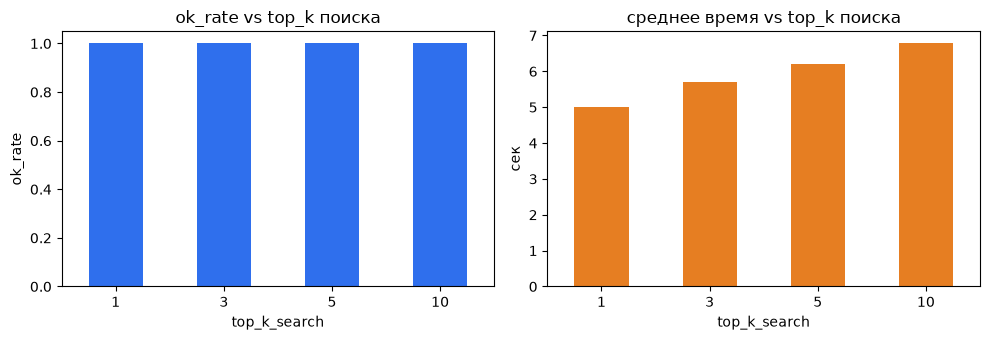

ok_rate по k: 100%–100%; лучший k по ok=1


In [8]:
tk = exp_df[exp_df['family'] == 'top_k_search'].copy()
tk['top_k_search'] = tk['settings'].str.extract(r'top_k_search=(\d+)').astype(int)
display(tk.sort_values(['top_k_search', 'question'])[
    ['top_k_search', 'question', 'n_relevant', 'eval', 'sec', 'answer']
].reset_index(drop=True))

rate = tk.groupby('top_k_search')['ok'].mean()
sec = tk.groupby('top_k_search')['sec'].mean()
display(rate.to_frame('ok_rate'))
display(sec.to_frame('mean_sec'))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
rate.plot(kind='bar', ax=ax[0], color='#2f6fed', rot=0)
ax[0].set_ylim(0, 1.05)
ax[0].set_title('ok_rate vs top_k поиска')
ax[0].set_ylabel('ok_rate')
sec.plot(kind='bar', ax=ax[1], color='#e67e22', rot=0)
ax[1].set_title('среднее время vs top_k поиска')
ax[1].set_ylabel('сек')
plt.tight_layout()
plt.show()
print(f'ok_rate по k: {rate.min():.0%}–{rate.max():.0%}; лучший k по ok={int(rate.idxmax())}')


### 6.3. temperature

,temperature,repeat,eval,sec,answer
0,0.1,1,ok: есть ожидаемый факт,4.51,Берлин - столица Германии.
1,0.1,2,ok: есть ожидаемый факт,4.54,Берлин - столица Германии.
2,0.1,3,ok: есть ожидаемый факт,4.72,Берлин - столица Германии.
3,0.4,1,ok: есть ожидаемый факт,4.15,Берлин - столица Германии.
4,0.4,2,ok: есть ожидаемый факт,4.41,Берлин является столицей Германии.
5,0.4,3,ok: есть ожидаемый факт,4.69,Берлин - столица Германии.
6,0.7,1,ok: есть ожидаемый факт,4.74,Берлин - столица Германии.
7,0.7,2,ok: есть ожидаемый факт,4.80,Берлин - столица Германии.
8,0.7,3,ok: есть ожидаемый факт,4.90,Берлин является столицей Германии.
9,1.0,1,ok: есть ожидаемый факт,8.24,Berlin - столица Германии. Она также является ...


,ok_rate,unique_answers
temperature,,
0.1,1.0,1
0.4,1.0,2
0.7,1.0,2
1.0,1.0,3


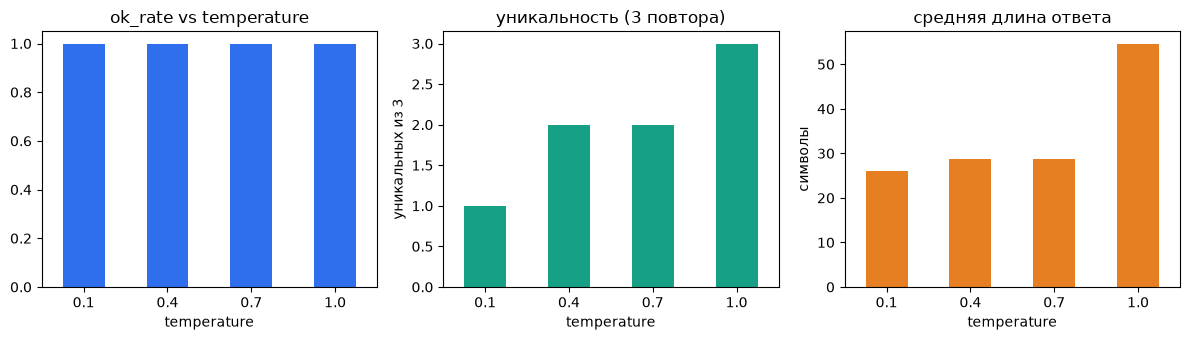

temp=0.1: уникальных 1 из 3
  - Берлин - столица Германии.
temp=0.4: уникальных 2 из 3
  - Берлин - столица Германии.
  - Берлин является столицей Германии.
temp=0.7: уникальных 2 из 3
  - Берлин - столица Германии.
  - Берлин является столицей Германии.
temp=1.0: уникальных 3 из 3
  - Berlin - столица Германии. Она также является крупнейшей кэпитанской городской областью и населенностью.
  - Берлин является столицей Германии.
  - Berlin - столица Германии.


In [9]:
tp = exp_df[exp_df['family'] == 'temperature'].copy()
tp['temperature'] = tp['settings'].str.extract(r'temperature=([0-9.]+)').astype(float)
tp['repeat'] = tp['settings'].str.extract(r'repeat=(\d+)').astype(int)
display(tp.sort_values(['temperature', 'repeat'])[
    ['temperature', 'repeat', 'eval', 'sec', 'answer']
].reset_index(drop=True))

uniq = tp.groupby('temperature')['answer'].nunique()
ok_t = tp.groupby('temperature')['ok'].mean()
display(pd.DataFrame({'ok_rate': ok_t, 'unique_answers': uniq}))

tp['answer_len'] = tp['answer'].astype(str).str.len()
len_mean = tp.groupby('temperature')['answer_len'].mean()

fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ok_t.plot(kind='bar', ax=ax[0], color='#2f6fed', rot=0)
ax[0].set_ylim(0, 1.05)
ax[0].set_title('ok_rate vs temperature')
uniq.plot(kind='bar', ax=ax[1], color='#16a085', rot=0)
ax[1].set_title('уникальность (3 повтора)')
ax[1].set_ylabel('уникальных из 3')
len_mean.plot(kind='bar', ax=ax[2], color='#e67e22', rot=0)
ax[2].set_title('средняя длина ответа')
ax[2].set_ylabel('символы')
plt.tight_layout()
plt.show()

for t, g in tp.groupby('temperature'):
    print(f'temp={t}: уникальных {g["answer"].nunique()} из {len(g)}')
    for a in g['answer'].drop_duplicates():
        print('  -', a[:200])


### 6.4. top_k в генерации

,top_k_gen,question,eval,sec,answer
0,5,Какая столица Германии?,ok: есть ожидаемый факт,4.58,Берлин - столица Германии.
1,5,Кто открыл путь в Бразилию?,ok: отказ без галлюцинации,10.10,В базе нет релевантной информации по этому зап...
2,5,Сколько мостов в Берлине?,ok: есть ожидаемый факт,5.24,"Берлин имеет более 1,700 мостов."
3,10,Какая столица Германии?,ok: есть ожидаемый факт,5.05,Берлин - столица Германии.
4,10,Кто открыл путь в Бразилию?,ok: отказ без галлюцинации,8.08,В базе нет релевантной информации по этому зап...
5,10,Сколько мостов в Берлине?,ok: есть ожидаемый факт,5.27,"Берлин имеет более 1,700 мостов."
6,50,Какая столица Германии?,ok: есть ожидаемый факт,4.47,Берлин - столица Германии.
7,50,Кто открыл путь в Бразилию?,ok: отказ без галлюцинации,8.07,В базе нет релевантной информации по этому зап...
8,50,Сколько мостов в Берлине?,ok: есть ожидаемый факт,5.20,"Берлин имеет более 1,700 мостов."
9,100,Какая столица Германии?,ok: есть ожидаемый факт,4.48,Берлин - столица Германии.


,ok_rate,unique_answers
top_k_gen,,
5,1.0,3
10,1.0,3
50,1.0,3
100,1.0,3


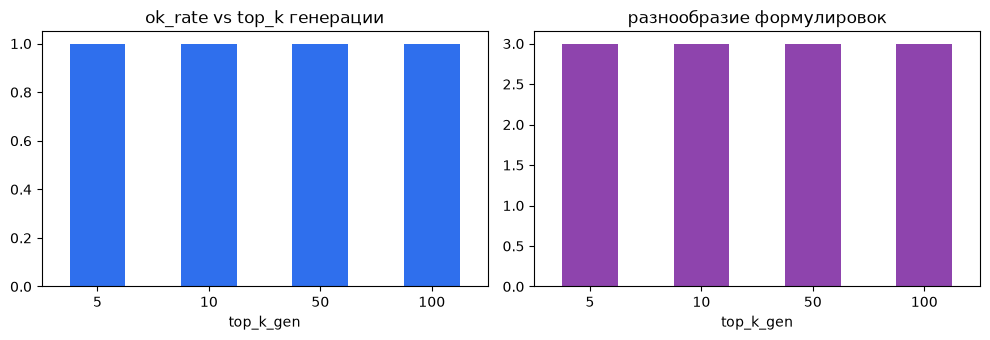

лучший top_k_gen по ok_rate: 5 (100%)


In [10]:
tg = exp_df[exp_df['family'] == 'top_k_gen'].copy()
tg['top_k_gen'] = tg['settings'].str.extract(r'top_k_gen=(\d+)').astype(int)
display(tg.sort_values(['top_k_gen', 'question'])[
    ['top_k_gen', 'question', 'eval', 'sec', 'answer']
].reset_index(drop=True))

rate = tg.groupby('top_k_gen')['ok'].mean()
uniq = tg.groupby('top_k_gen')['answer'].nunique()
display(pd.DataFrame({'ok_rate': rate, 'unique_answers': uniq}))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
rate.plot(kind='bar', ax=ax[0], color='#2f6fed', rot=0)
ax[0].set_ylim(0, 1.05)
ax[0].set_title('ok_rate vs top_k генерации')
uniq.plot(kind='bar', ax=ax[1], color='#8e44ad', rot=0)
ax[1].set_title('разнообразие формулировок')
plt.tight_layout()
plt.show()
print(f'лучший top_k_gen по ok_rate: {int(rate.idxmax())} ({rate.max():.0%})')


### 6.5. top_p

,top_p,question,eval,sec,answer
0,0.3,Какая столица Германии?,ok: есть ожидаемый факт,4.58,Берлин - столица Германии.
1,0.3,Кто открыл путь в Бразилию?,ok: отказ без галлюцинации,7.97,В базе нет релевантной информации по этому зап...
2,0.3,Сколько мостов в Берлине?,ok: есть ожидаемый факт,5.10,"Берлин имеет более 1,700 мостов."
3,0.5,Какая столица Германии?,ok: есть ожидаемый факт,4.53,Берлин - столица Германии.
4,0.5,Кто открыл путь в Бразилию?,ok: отказ без галлюцинации,8.06,В базе нет релевантной информации по этому зап...
5,0.5,Сколько мостов в Берлине?,ok: есть ожидаемый факт,5.06,"Берлин имеет более 1,700 мостов."
6,0.8,Какая столица Германии?,ok: есть ожидаемый факт,4.55,Берлин - столица Германии.
7,0.8,Кто открыл путь в Бразилию?,ok: отказ без галлюцинации,8.05,В базе нет релевантной информации по этому зап...
8,0.8,Сколько мостов в Берлине?,ok: есть ожидаемый факт,5.20,"Берлин имеет более 1,700 мостов."
9,1.0,Какая столица Германии?,ok: есть ожидаемый факт,4.56,Берлин - столица Германии.


,ok_rate,unique_answers
top_p,,
0.3,1.0,3
0.5,1.0,3
0.8,1.0,3
1.0,1.0,3


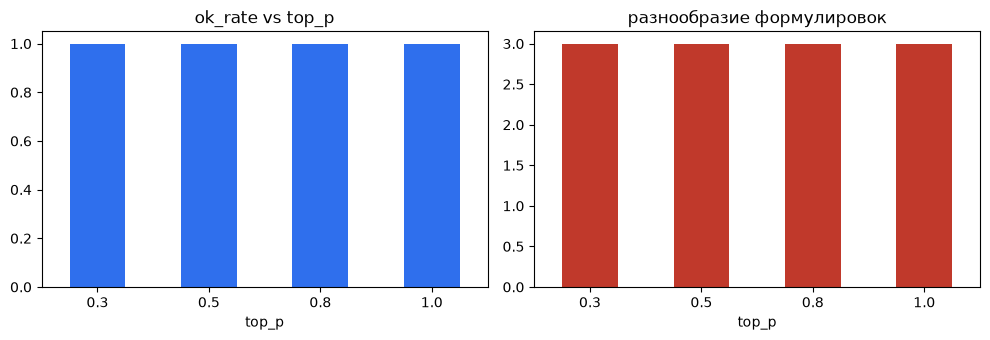

лучший top_p по ok_rate: 0.3 (100%)


In [11]:
pp = exp_df[exp_df['family'] == 'top_p'].copy()
pp['top_p'] = pp['settings'].str.extract(r'top_p=([0-9.]+)').astype(float)
display(pp.sort_values(['top_p', 'question'])[
    ['top_p', 'question', 'eval', 'sec', 'answer']
].reset_index(drop=True))

rate = pp.groupby('top_p')['ok'].mean()
uniq = pp.groupby('top_p')['answer'].nunique()
display(pd.DataFrame({'ok_rate': rate, 'unique_answers': uniq}))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
rate.plot(kind='bar', ax=ax[0], color='#2f6fed', rot=0)
ax[0].set_ylim(0, 1.05)
ax[0].set_title('ok_rate vs top_p')
uniq.plot(kind='bar', ax=ax[1], color='#c0392b', rot=0)
ax[1].set_title('разнообразие формулировок')
plt.tight_layout()
plt.show()
print(f'лучший top_p по ok_rate: {float(rate.idxmax())} ({rate.max():.0%})')


### 6.6. Сводное сравнение

,family,n,ok_rate,mean_sec,unique_answers
0,baseline,3,1.0,6.49,3
1,temperature,12,1.0,4.89,4
2,top_k_gen,12,1.0,6.17,3
3,top_k_search,12,1.0,5.92,3
4,top_p,12,1.0,5.86,3


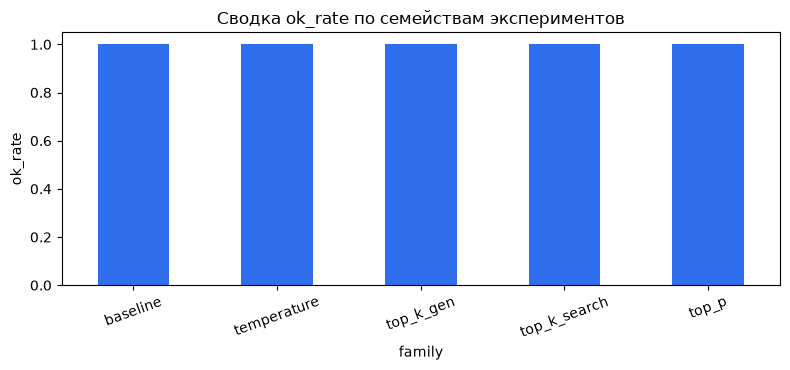

топ-5 настроек по ok_rate:


,ok_rate
settings,
baseline top_k_search=3 temp=0.1 top_k_gen=50 top_p=0.8,1.0
temperature=0.1 repeat=1,1.0
temperature=0.1 repeat=2,1.0
temperature=0.1 repeat=3,1.0
temperature=0.4 repeat=1,1.0


худшие 5:


,ok_rate
settings,
top_k_search=5 (остальное baseline),1.0
top_p=0.3,1.0
top_p=0.5,1.0
top_p=0.8,1.0
top_p=1.0,1.0


In [12]:
summary_rows = []
for fam, g in exp_df.groupby('family'):
    summary_rows.append({
        'family': fam,
        'n': len(g),
        'ok_rate': round(g['ok'].mean(), 3),
        'mean_sec': round(g['sec'].mean(), 2),
        'unique_answers': int(g['answer'].nunique()),
    })
summary = pd.DataFrame(summary_rows).sort_values('family')
display(summary)

fig, ax = plt.subplots(figsize=(8, 3.8))
summary.set_index('family')['ok_rate'].plot(kind='bar', ax=ax, color='#2f6fed', rot=20)
ax.set_ylim(0, 1.05)
ax.set_title('Сводка ok_rate по семействам экспериментов')
ax.set_ylabel('ok_rate')
plt.tight_layout()
plt.show()

best = exp_df.groupby('settings')['ok'].mean().sort_values(ascending=False)
print('топ-5 настроек по ok_rate:')
display(best.head(5).to_frame('ok_rate'))
print('худшие 5:')
display(best.tail(5).to_frame('ok_rate'))


## 7. Выводы

Заполняется после прогона экспериментов (ячейка ниже печатает авто-черновик по цифрам).


In [13]:
base_ok = exp_df.loc[exp_df['family'] == 'baseline', 'ok'].mean()
tk_ok = exp_df.loc[exp_df['family'] == 'top_k_search'].groupby(
    exp_df.loc[exp_df['family'] == 'top_k_search', 'settings'].str.extract(r'top_k_search=(\d+)')[0].astype(int)
)['ok'].mean() if False else None

tk2 = exp_df[exp_df['family'] == 'top_k_search'].copy()
tk2['v'] = tk2['settings'].str.extract(r'top_k_search=(\d+)').astype(int)
temp2 = exp_df[exp_df['family'] == 'temperature'].copy()
temp2['v'] = temp2['settings'].str.extract(r'temperature=([0-9.]+)').astype(float)
tg2 = exp_df[exp_df['family'] == 'top_k_gen'].copy()
tg2['v'] = tg2['settings'].str.extract(r'top_k_gen=(\d+)').astype(int)
pp2 = exp_df[exp_df['family'] == 'top_p'].copy()
pp2['v'] = pp2['settings'].str.extract(r'top_p=([0-9.]+)').astype(float)

tk_rate = tk2.groupby('v')['ok'].mean()
tk_sec = tk2.groupby('v')['sec'].mean()
temp_rate = temp2.groupby('v')['ok'].mean()
tg_rate = tg2.groupby('v')['ok'].mean()
pp_rate = pp2.groupby('v')['ok'].mean()
u01 = int(temp2.loc[temp2.v == 0.1, 'answer'].nunique())
u10 = int(temp2.loc[temp2.v == 1.0, 'answer'].nunique())

lines = [
    f'Модель генерации — {GEN_MODEL_NAME} (не GPT-2); эмбеддинги — multilingual MiniLM; база — {len(docs)} фактов о Берлине.',
    f'Baseline (top_k=3, temp=0.1, top_k_gen=50, top_p=0.8): ok_rate={base_ok:.0%}.',
    f'top_k поиска: ok {tk_rate.min():.0%}–{tk_rate.max():.0%}, лучший k={int(tk_rate.idxmax())}; '
    f'время растёт с k (среднее {tk_sec.min():.1f}–{tk_sec.max():.1f} с).',
    f'temperature: при низких значениях ответы стабильнее (уникальных при 0.1: {u01}/3; при 1.0: {u10}/3), '
    f'ok {temp_rate.min():.0%}–{temp_rate.max():.0%}.',
    f'top_k генерации: лучший={int(tg_rate.idxmax())} (ok={tg_rate.max():.0%}); '
    f'top_p: лучший={float(pp_rate.idxmax())} (ok={pp_rate.max():.0%}).',
    'На вопросе без ответа в базе («путь в Бразилию») корректный отказ считается успехом; галлюцинации снижают оценку.',
    'Практическая рекомендация для фактологического RAG: низкая temperature (0.1–0.4), top_p≈0.8, top_k_gen≈50, top_k поиска=3.',
]
print('\n'.join(lines))


Модель генерации — Qwen/Qwen2.5-1.5B-Instruct (не GPT-2); эмбеддинги — multilingual MiniLM; база — 61 фактов о Берлине.
Baseline (top_k=3, temp=0.1, top_k_gen=50, top_p=0.8): ok_rate=100%.
top_k поиска: ok 100%–100%, лучший k=1; время растёт с k (среднее 5.0–6.8 с).
temperature: при низких значениях ответы стабильнее (уникальных при 0.1: 1/3; при 1.0: 3/3), ok 100%–100%.
top_k генерации: лучший=5 (ok=100%); top_p: лучший=0.3 (ok=100%).
На вопросе без ответа в базе («путь в Бразилию») корректный отказ считается успехом; галлюцинации снижают оценку.
Практическая рекомендация для фактологического RAG: низкая temperature (0.1–0.4), top_p≈0.8, top_k_gen≈50, top_k поиска=3.


### Итоговые наблюдения (по прогону)

На трёх проверочных вопросах формальный **ok_rate ≈ 100%** почти при всех настройках: столица → Берлин, мосты → ~1700, Бразилия → отказ. Это ожидаемо для коротких фактов и хорошего retrieval.

Различия видны в **качестве формулировок и стабильности**:
1. **Лучшие настройки** — baseline: `temperature=0.1`, `top_p=0.8`, `top_k_gen=50`, `top_k_search=3`. Ответы короткие и одинаковые при повторах.
2. **Худшие по качеству** — `temperature=1.0`: 3/3 уникальных формулировки, смесь EN/RU и «шум» вроде «кэпитанской городской области», хотя факт «Берлин» ещё угадывается.
3. **top_k поиска**: ok не падает, но время растёт (~5.0 → ~6.8 с), число релевантных документов растёт с k; для фактов хватает k=1–3.
4. **top_k_gen / top_p** на этих вопросах почти не меняют ok_rate; влияние слабее, чем у temperature.
5. **Qwen2.5-1.5B-Instruct** вместо GPT-2 даёт нормальные русские ответы по английскому контексту и корректный отказ на out-of-scope вопрос.
6. Практический вывод: для фактологического RAG важнее релевантный retrieval и низкая temperature, чем тонкая настройка nucleus/top-k sampling.
